In [1]:
import jax
import jax.numpy as jnp

import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive

import matplotlib.pyplot as plt
import arviz as az
import arviz_plots as azp

## Generate fake data

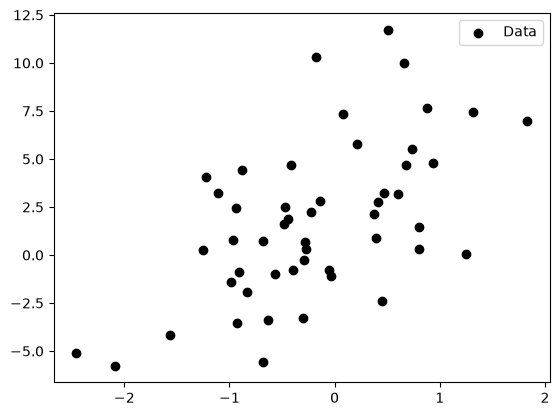

In [2]:
key = jax.random.PRNGKey(42)
n = 50

true_intercept = 2.
true_slope = 3.
true_sigma = 3.

key, sub_key = jax.random.split(key)
x = jax.random.normal(sub_key, shape=(n,) )
key, sub_key = jax.random.split(key)
y = true_slope * x + true_intercept + true_sigma * jax.random.normal(sub_key, shape=(n,))

plt.figure()
plt.scatter(x, y, label="Data", color='k')
plt.legend()
plt.show()

## Define model

In [3]:
def model(x, y=None):
    intercept = numpyro.sample("intercept", dist.Normal(0, 10))

    slope = numpyro.sample("slope", dist.Normal(0, 10))

    sigma = numpyro.sample("sigma", dist.HalfNormal(5))

    mu = intercept + slope * x

    with numpyro.plate("data", len(x)):
        numpyro.sample("obs", dist.Normal(mu, sigma), obs=y)

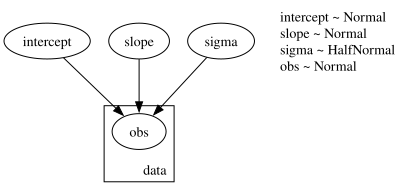

In [4]:
numpyro.render_model(model, model_kwargs={"x": x}, render_distributions=True, )

## Doing inference

In [5]:
kernel = NUTS(model)
mcmc = MCMC(kernel, num_warmup=500, num_samples=10000)
key, sub_key = jax.random.split(key)
mcmc.run(sub_key, x=x, y=y)
mcmc.print_summary()

sample: 100%|██████████| 10500/10500 [00:03<00:00, 3263.81it/s, 7 steps of size 6.77e-01. acc. prob=0.92]



                 mean       std    median      5.0%     95.0%     n_eff     r_hat
  intercept      2.24      0.50      2.25      1.42      3.09   7358.73      1.00
      sigma      3.43      0.36      3.40      2.85      4.00   8306.68      1.00
      slope      2.69      0.57      2.69      1.74      3.62   9698.58      1.00

Number of divergences: 0


In [6]:
posterior_samples = mcmc.get_samples()
idata = az.from_numpyro(mcmc)

<Figure size 640x480 with 0 Axes>

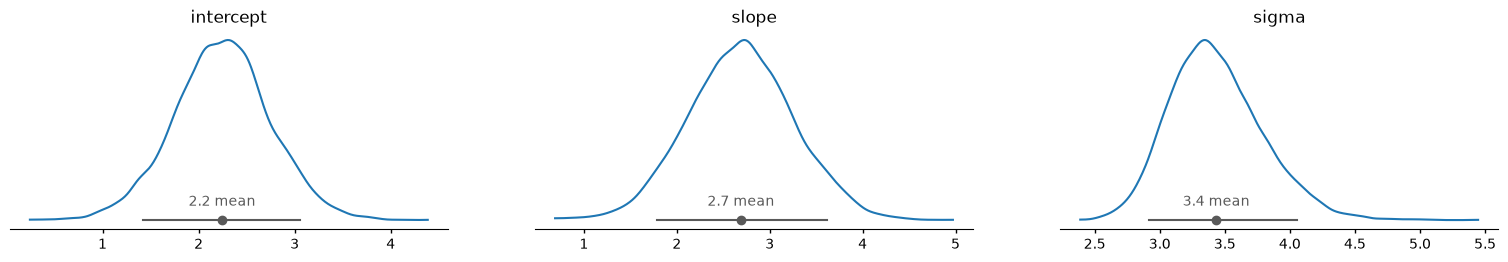

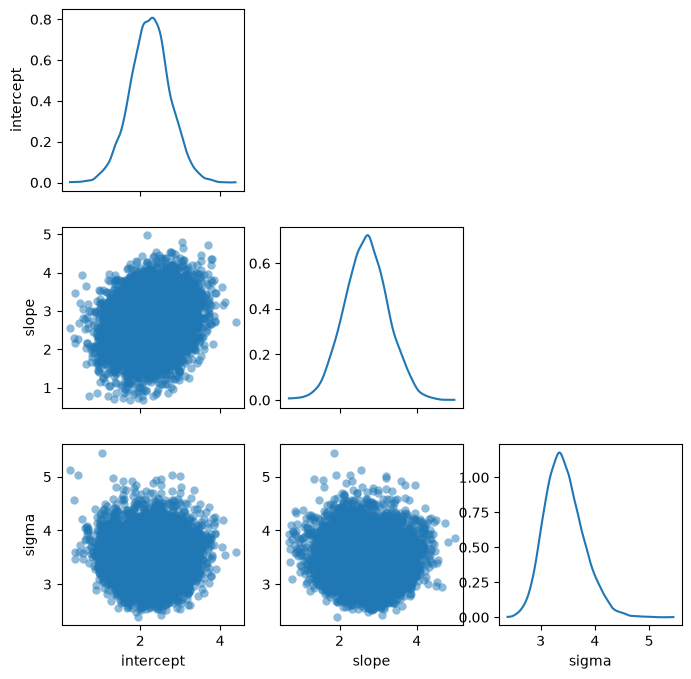

In [7]:
plt.figure()
az.plot_dist(idata, var_names=["intercept", "slope", "sigma"])
azp.plot_pair(idata, var_names=["intercept", "slope", "sigma"])
plt.gcf().set_size_inches(8, 8)
plt.show()

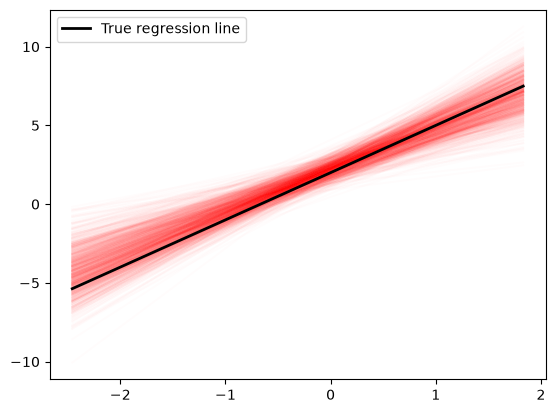

In [8]:
x_plot = jnp.linspace(x.min(), x.max(), 100)
y_true = true_intercept + true_slope * x_plot
n_lines = 1000

key, subkey = jax.random.split(key)
idx = jax.random.choice(subkey, len(posterior_samples["slope"]), shape=(n_lines,), replace=False)

plt.figure()
for i in idx:
    intercept_i = posterior_samples["intercept"][i]
    slope_i = posterior_samples["slope"][i]
    y_line = intercept_i + slope_i * x_plot
    plt.plot(x_plot, y_line, alpha=0.01, color='red')
plt.plot(x_plot, y_true, linewidth=2, label="True regression line", color='black')
plt.legend()
plt.show()

## Sample new points

In [9]:
key, sub_key = jax.random.split(key)
posterior_predictive = Predictive(model, posterior_samples=posterior_samples)
predictive_samples = posterior_predictive(sub_key, x=x)
y_new = predictive_samples['obs'][0,:]

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(x, y, color="black", label="Observed data")
plt.scatter(x, y_new, color="red", alpha=0.5, label="Posterior predictive sample")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.show()